# 01 · Data overview

**Question:** Which orders have complete delivery data, and what does an order's
lifecycle look like from purchase to delivery?

Why it matters: lateness can only be measured on orders that were delivered.
This notebook decides which orders the rest of the project analyses.

Source: the `order_delivery` view (`sql/01_order_delivery.sql`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

# Notebooks run from notebooks/, so add src/ to the import path.
sys.path.insert(0, str(Path.cwd().parent / "src"))
from db import query

sns.set_theme(style="whitegrid")

## 1. Order status

**Question:** How many orders are in each status, and how many count as delivered?

In [8]:
status = query("""
    SELECT order_status,
           COUNT(*)                              AS orders,
           COUNT(*) FILTER (WHERE is_delivered)  AS delivered_with_date
    FROM order_delivery
    GROUP BY order_status
    ORDER BY orders DESC
""")
status["share_of_orders"] = (status["orders"] / status["orders"].sum()).round(4)
status

,order_status,orders,delivered_with_date,share_of_orders
0,delivered,96478,96470,0.9702
1,shipped,1107,0,0.0111
2,canceled,625,0,0.0063
3,unavailable,609,0,0.0061
4,invoiced,314,0,0.0032
5,processing,301,0,0.0030
6,created,5,0,0.0001
7,approved,2,0,0.0000


**Observations:**

- 97.0% of the 99,441 orders are `delivered`; the remaining 2,963 (~3%) are
  spread across 7 other statuses, the largest being `shipped` (1,107).
- 8 orders are marked `delivered` but have no delivery date, so their
  lateness cannot be measured.
- No order outside `delivered` has a delivery date. For `canceled` and
  `unavailable` this is because the order was never sent; for `shipped` it
  likely means the order was still in transit when the data was collected,
  or was lost (this table can't tell which).
- **Decision:** lateness will be measured on the 96,470 orders that are
  delivered and have a delivery date. Dropping the rest loses only 3.0% of
  the data, so sample size is not a concern.
- **Caveat:** the dropped `shipped` orders may include the worst deliveries
  (never arrived), so excluding them could make lateness look slightly
  better than it is. Section 1b checks this: most are likely lost.

### 1b. How old are the `shipped` orders?

**Question:** Were the 1,107 `shipped` orders still in transit when the data
was collected (bought shortly before the data ends), or are they old orders
that never arrived?

In [ ]:
# Summary: how far before the end of the data were shipped orders placed?
summary = query("""
    SELECT (SELECT MAX(order_purchase_timestamp) FROM order_delivery)::date AS last_purchase_in_data,
           MIN(order_purchase_timestamp)::date                              AS oldest_shipped,
           MAX(order_purchase_timestamp)::date                              AS newest_shipped,
           ROUND(AVG(EXTRACT(EPOCH FROM
               (SELECT MAX(order_purchase_timestamp) FROM order_delivery)
               - order_purchase_timestamp) / 86400))                        AS avg_days_before_data_end
    FROM order_delivery
    WHERE order_status = 'shipped'
""")
display(summary)

# Detail: shipped orders per purchase month
shipped_by_month = query("""
    SELECT date_trunc('month', order_purchase_timestamp)::date AS purchase_month,
           COUNT(*)                                            AS shipped_orders
    FROM order_delivery
    WHERE order_status = 'shipped'
    GROUP BY 1
    ORDER BY 1
""")

ax = shipped_by_month.plot(x="purchase_month", y="shipped_orders", kind="bar",
                           legend=False, figsize=(10, 4))
ax.set(title="Shipped (never delivered) orders by purchase month",
       xlabel="", ylabel="Orders")
plt.show()

**Observations:**

- `shipped` orders are spread across the **whole period** (Sep 2016 – Sep 2018),
  not bunched at the end. On average they were bought **316 days** before the
  data ends (17 Oct 2018).
- Only **1** was bought in Sep 2018; every other month has 16–133. Since 95%
  of orders arrive within ~29 days (section 3), almost all of these should
  have arrived long before the data was collected.
- **Conclusion:** most `shipped` orders were **never delivered** (lost, or
  their status was never updated), not still in transit.
- **Impact:** excluding them leaves out ~1.1% of orders that are likely
  failed deliveries, so measured lateness is slightly **optimistic**.
  Mention this as a limitation in the README.

## 2. Coverage over time

**Question:** Is the number of orders per month stable, or are some months
too sparse to trust (especially at the start and end of the dataset)?

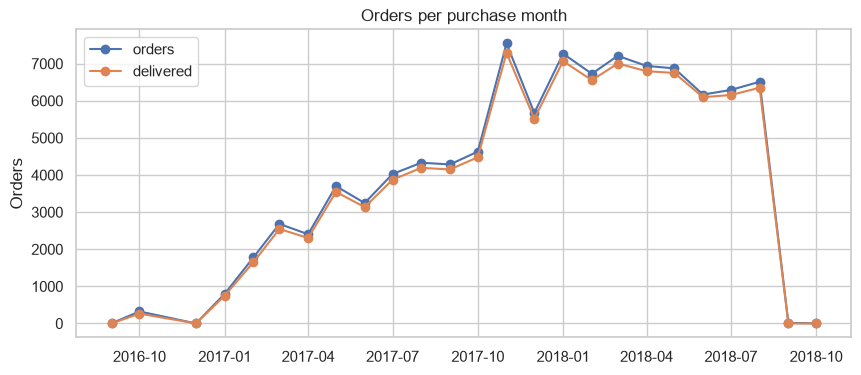

,month,orders,delivered
0,2016-09-01,4,1
1,2016-10-01,324,265
2,2016-12-01,1,1
3,2017-01-01,800,750
4,2017-02-01,1780,1653
5,2017-03-01,2682,2546
6,2017-04-01,2404,2303
7,2017-05-01,3700,3545
8,2017-06-01,3245,3135
9,2017-07-01,4026,3872


In [15]:
monthly = query("""
    SELECT date_trunc('month', order_purchase_timestamp)::date AS month,
           COUNT(*)                                            AS orders,
           COUNT(*) FILTER (WHERE is_delivered)                AS delivered
    FROM order_delivery
    GROUP BY 1
    ORDER BY 1
""")

ax = monthly.plot(x="month", y=["orders", "delivered"], marker="o", figsize=(10, 4))
ax.set(title="Orders per purchase month", xlabel="", ylabel="Orders")
plt.show()
monthly

**Observations:**

- **Start (2016):** very sparse and irregular: 4 orders in Sep, 324 in Oct,
  **no orders at all in Nov**, and 1 in Dec. These months are too small to
  trust any monthly rate.
- **End (2018):** Sep has 16 orders and Oct has 4, and **none of them were
  delivered**. The data effectively ends in Aug 2018; these orders had no
  time to arrive before the data was collected.
- **Main period:** volume grows steadily from 800 orders in Jan 2017 to
  ~4,000–4,600/month in mid/late 2017, then stays roughly flat at
  ~6,200–7,300/month from Jan to Aug 2018.
- **Unusual month:** Nov 2017 has 7,544 orders, much higher than Oct (4,631)
  and Dec (5,673), likely Black Friday (24 Nov 2017).
- In every month, delivered orders are only slightly below total orders
  (about 2–7% gap), consistent with the ~3% non-delivered orders in section 1.
- **Decision:** use orders purchased **Jan 2017 – Aug 2018** for analysis
  over time. 2016 is too sparse and has a missing month; Sep–Oct 2018 have
  no delivered orders. This removes 267 delivered orders (all from 2016),
  about 0.3% of the 96,470.


## 3. Lifecycle durations

**Question:** For delivered orders, how many days does each stage take:
approval, handing to the carrier, and carrier to customer?

In [16]:
stages = query("""
    SELECT EXTRACT(EPOCH FROM order_approved_at             - order_purchase_timestamp)     / 86400 AS purchase_to_approval,
           EXTRACT(EPOCH FROM order_delivered_carrier_date  - order_approved_at)            / 86400 AS approval_to_carrier,
           EXTRACT(EPOCH FROM order_delivered_customer_date - order_delivered_carrier_date) / 86400 AS carrier_to_customer,
           EXTRACT(EPOCH FROM order_delivered_customer_date - order_purchase_timestamp)     / 86400 AS purchase_to_customer
    FROM order_delivery
    WHERE is_delivered
""")
stages.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(2)

,purchase_to_approval,approval_to_carrier,carrier_to_customer,purchase_to_customer
count,96456.00,96455.00,96469.00,96470.00
mean,0.43,2.80,9.33,12.56
std,0.86,3.54,8.76,9.55
min,0.00,-171.22,-16.10,0.53
5%,0.01,0.25,1.12,3.02
25%,0.01,0.87,4.10,6.77
50%,0.01,1.82,7.10,10.22
75%,0.60,3.57,12.03,15.72
95%,2.01,8.09,24.20,29.27
max,30.89,125.76,205.19,209.63


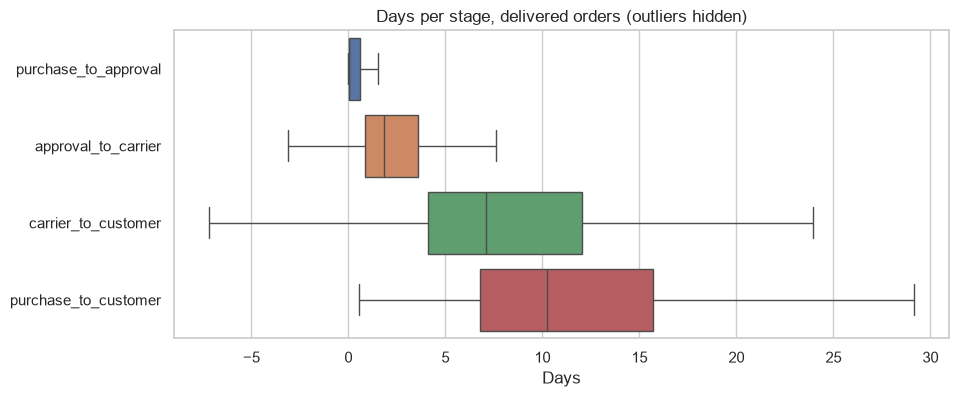

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=stages, orient="h", showfliers=False, ax=ax)
ax.set(title="Days per stage, delivered orders (outliers hidden)", xlabel="Days")
plt.show()

**Observations:**

- Typical delivery takes **10.2 days** (median); 95% arrive within **29 days**.
  Mean (12.6) > median → a few very slow orders (max 210 days).
- Slowest stage is **carrier → customer** (median 7.1 days, ~70% of total).
  Approval is near-instant (~15 min); seller → carrier takes ~1.8 days.
- **Data issues:** some negative durations (impossible) and 15 orders with a
  missing approval or carrier date. See section 4.
- **Decision:** keep slow orders; they are the late deliveries we study.


## 4. Timestamps out of order

**Question:** Are there delivered orders whose dates happen in an impossible
order? Each row is one rule; `orders` is how many orders break it.

In [17]:
query("""
    SELECT 'approved before purchase'          AS rule, COUNT(*) FILTER (WHERE order_approved_at             < order_purchase_timestamp)     AS orders FROM order_delivery WHERE is_delivered
    UNION ALL
    SELECT 'carrier handoff before approval',            COUNT(*) FILTER (WHERE order_delivered_carrier_date  < order_approved_at)            FROM order_delivery WHERE is_delivered
    UNION ALL
    SELECT 'customer delivery before carrier handoff',   COUNT(*) FILTER (WHERE order_delivered_customer_date < order_delivered_carrier_date) FROM order_delivery WHERE is_delivered
    UNION ALL
    SELECT 'customer delivery before purchase',          COUNT(*) FILTER (WHERE order_delivered_customer_date < order_purchase_timestamp)     FROM order_delivery WHERE is_delivered
    UNION ALL
    SELECT 'delivered but missing approval or carrier date', COUNT(*) FILTER (WHERE order_approved_at IS NULL OR order_delivered_carrier_date IS NULL) FROM order_delivery WHERE is_delivered
""")

,rule,orders
0,delivered but missing approval or carrier date,15
1,approved before purchase,0
2,carrier handoff before approval,1350
3,customer delivery before carrier handoff,23
4,customer delivery before purchase,0


**Observations:**

- 1,373 delivered orders have out-of-order middle dates: 1,350 carrier
  handoff before approval (897 of them by less than 1 day, likely a
  recording glitch) and 23 delivered before carrier handoff.
- 15 delivered orders are missing an approval or carrier date.
- Purchase and delivery dates are never out of order (0 cases), so
  **lateness is valid for all 96,470 delivered orders**.
- **Decision:** keep these orders. Treat stage durations (section 3) as
  unreliable for them; they are not used for lateness or as model
  features (not known at purchase).

## Decisions from this notebook


1. **Scope:** measure lateness on the **96,470** orders that are `delivered`
   and have a delivery date (97% of all orders).
2. **Date range:** for analysis over time, use purchases from
   **Jan 2017 – Aug 2018**. 2016 is too sparse and has a missing month;
   Sep–Oct 2018 have no delivered orders. This drops 267 delivered orders (~0.3%).
3. **Keep slow orders** (up to 210 days). They are the late deliveries this
   project studies, not outliers.
4. **Keep orders with out-of-order middle dates** (1,373). Purchase and
   delivery dates are always valid, so their lateness label is correct.
5. **Not model features:** approval and carrier handoff dates; they happen
   after purchase (leakage).
6. **`shipped` orders (1,107):** most are old and likely never delivered
   (section 1b). They stay excluded from lateness, noted as a limitation:
   measured lateness is slightly optimistic.